# SAMS Vision: distance estimation training

This notebook trains the residual distance network used by `monitoring/services/distance_estimation.py`. Live inference reads calibration from `models/vision/distance/calib.json` (`fy_px`, `fy_image_h`, `person_height_m`, `tof_near_m`, `hidden`) and serves, in this order: `site/model.pt` if it exists, otherwise the residual experiment folder with the lowest `metrics_test.mae`. Only the experiment this notebook promotes is given `metrics_test`, so the live choice is the notebook's choice.

Distance is modeled as **Z = Z0 * exp(delta)**, where Z0 is the pinhole prior `fy * H / h_px` and delta is the network's correction.

## Dataset

[Human tracking dataset](https://data.mendeley.com/datasets/493s6f753v/2) (DOI `10.17632/493s6f753v.2`): people filmed by a ring of calibrated cameras, with 2D keypoints per camera and 3D landmarks, so the true camera-to-person distance is known for every view.

## What changed from the first version, and why

| Change | Why |
|--------|-----|
| Z0 uses the live `PERSON_HEIGHT_M` and one calibrated `fy`, not each subject's true height and each camera's own focal length | The live service knows neither. Training with the true values taught the network a correction it never needs and hid the height error it always meets |
| Boxes are the keypoint extent plus a random detector-like margin, clipped to the frame; keypoints outside the frame are dropped | The live box comes from the person detector, and a close worker is cut off by the frame edge. The old table never showed either |
| Close-range rows (0.8 to 1.5 m) are generated | The ToF sensor covers only the person in its beam; everyone else near the machine is measured by this network, and the old table had no row below 1.8 m |
| Walking (GAIT) and SQUATS are used, not only A-POSE and RUNNING | Workers walk, bend and crouch; a crouching worker's apparent height is the hard case |
| Only the 17 keypoints COCO pose models produce are used | The live pose model is COCO-17; MediaPipe's extra face, hand and foot points made the training boxes and confidences differ |
| Selection by leave-one-subject-out cross-validation; one subject held out as test | The old notebook picked the winner by test MAE and early-stopped on random rows of the training subjects |
| The site fine-tune splits by trial | Neighbouring rows of one trial are near-identical, so a random row split leaks |

## Steps

| Section | Step |
|---------|------|
| 0 | Setup, configuration, FEATURE_NAMES |
| 1 | Download every subject and movement the file index offers |
| 2 | Build the labelled feature table the way live inference builds features (cached on Drive), and preview it |
| 3 | EDA, previews, PCA |
| 4 | Test subject, and cross-validation folds over the other subjects |
| 5 | Models and training utilities |
| 6 | Experiments, scored by cross-validation |
| 7 | Choose, test once, export `calib.json`, weights, and a model card |
| 8 | Fine-tune on this site's labelled rows (`site/`) |
| 9 | Limitations |

## Rules

1. Every split groups by **subject**, so no person is on both sides.
2. `FEATURE_NAMES` and the feature code match `distance_estimation.py`.
3. `ResidualDistanceMLP` matches the live module layout.
4. The test subject is scored once, after the choice.
5. Tables as DataFrames with CSV; charts as PNG.

## 0. Setup

### 0.1 Paths

In [1]:
from pathlib import Path

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    SAMS_ROOT = Path("/content/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")

for folder in [
    SAMS_ROOT / "datasets" / "vision" / "distance" / "mendeley_493s6f753v",
    SAMS_ROOT / "models" / "vision" / "distance",
    SAMS_ROOT / "results" / "vision" / "distance",
]:
    folder.mkdir(parents=True, exist_ok=True)

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "distance"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "distance"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "distance" / "mendeley_493s6f753v"

Mounted at /content/drive


### 0.2 Packages

In [3]:
import subprocess, sys
PACKAGES = ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "scipy", "torch", "tqdm"]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])

In [4]:
import gc
import json
import math
import time
import warnings
from collections import Counter
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from numpy.linalg import svd
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

DEVICE: cuda


### 0.3 Configuration

In [5]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    here = Path.cwd().resolve()
    if (here / "manage.py").exists():
        DRIVE_ROOT = here
    elif (here.parent / "manage.py").exists():
        DRIVE_ROOT = here.parent
    else:
        DRIVE_ROOT = Path("./SAMS_drive_mirror")

MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "distance"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "distance"
DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "distance" / "mendeley_493s6f753v"

for folder in [MODELS_DIR, RESULTS_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)
print("DATA_DIR:   ", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/vision/distance
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/vision/distance
DATA_DIR:    /content/SAMS/datasets/vision/distance/mendeley_493s6f753v


In [6]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

HIDDEN = (64, 32)
MAX_EPOCHS = 150
PATIENCE = 15
LR = 1e-3
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 1024
LOG_EVERY = 10

PERSON_HEIGHT_M = 1.7
TOF_NEAR_M = 1.5
FY_PX_DEFAULT = 753.8742631289133

MOVEMENTS = ["A-POSE", "GAIT", "RUNNING", "SQUATS"]
VIRTUAL_DISTANCES = [0.8, 1.0, 1.2, 1.5, 1.8, 2.2, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0]
MAX_CAMERAS_PER_FRAME = 12
FRAME_STRIDE = 4
BOX_PAD_TOP = (0.04, 0.12)
BOX_PAD_BOTTOM = (0.01, 0.05)
BOX_PAD_SIDE = (0.03, 0.10)
TEST_SUBJECTS = 1
DISTANCE_BANDS_M = [0.0, 1.5, 3.0, 6.0, 100.0]

FEATURES_CACHE = DRIVE_ROOT / "datasets" / "vision" / "distance" / "distance_features_labeled.csv.gz"
POSE_METADATA = DRIVE_ROOT / "models" / "vision" / "pose" / "metadata.json"
KPT_CONF = 0.3
if POSE_METADATA.is_file():
    KPT_CONF = float((json.loads(POSE_METADATA.read_text()).get("operating_point") or {}).get("kpt_conf", KPT_CONF))

config_table = pd.DataFrame([
    {"setting": "SEED", "value": SEED, "meaning": "Random seed for splits, box margins and training"},
    {"setting": "HIDDEN", "value": str(HIDDEN), "meaning": "Residual MLP hidden layers (live calib.json)"},
    {"setting": "MAX_EPOCHS", "value": MAX_EPOCHS, "meaning": "Upper epoch limit"},
    {"setting": "PATIENCE", "value": PATIENCE, "meaning": "Epochs without a better held-out MAE before stopping"},
    {"setting": "LR", "value": LR, "meaning": "AdamW learning rate"},
    {"setting": "WEIGHT_DECAY", "value": WEIGHT_DECAY, "meaning": "AdamW weight decay"},
    {"setting": "BATCH_SIZE", "value": BATCH_SIZE, "meaning": "Rows per training step; the whole table sits on the GPU"},
    {"setting": "LOG_EVERY", "value": LOG_EVERY, "meaning": "Print training progress every n epochs"},
    {"setting": "FEATURES_CACHE", "value": str(FEATURES_CACHE), "meaning": "Feature table on Drive, reused by a later session built with the same settings"},
    {"setting": "PERSON_HEIGHT_M", "value": PERSON_HEIGHT_M, "meaning": "Stature in the pinhole prior, the same value the live service uses"},
    {"setting": "TOF_NEAR_M", "value": TOF_NEAR_M, "meaning": "Range the ToF sensor owns for the person in its beam"},
    {"setting": "FY_PX_DEFAULT", "value": FY_PX_DEFAULT, "meaning": "Focal length if no camera matrix is read"},
    {"setting": "MOVEMENTS", "value": ", ".join(MOVEMENTS), "meaning": "Recorded movements used: standing, walking, running, crouching"},
    {"setting": "VIRTUAL_DISTANCES", "value": str(VIRTUAL_DISTANCES), "meaning": "Distances each view is rescaled to (m), down to the close range the ToF beam misses"},
    {"setting": "MAX_CAMERAS_PER_FRAME", "value": MAX_CAMERAS_PER_FRAME, "meaning": "Camera views kept per recorded frame"},
    {"setting": "FRAME_STRIDE", "value": FRAME_STRIDE, "meaning": "Every n-th recorded frame is used; neighbours are near-identical"},
    {"setting": "BOX_PAD_TOP", "value": str(BOX_PAD_TOP), "meaning": "Detector box above the nose, as a share of keypoint height (random in this range)"},
    {"setting": "BOX_PAD_BOTTOM", "value": str(BOX_PAD_BOTTOM), "meaning": "Detector box below the ankles, as a share of keypoint height"},
    {"setting": "BOX_PAD_SIDE", "value": str(BOX_PAD_SIDE), "meaning": "Detector box beyond the outermost joints, as a share of keypoint width, each side"},
    {"setting": "KPT_CONF", "value": KPT_CONF, "meaning": "Joint confidence a keypoint needs, read from the pose model's operating point"},
    {"setting": "TEST_SUBJECTS", "value": TEST_SUBJECTS, "meaning": "Subjects held out as the test set"},
    {"setting": "DISTANCE_BANDS_M", "value": str(DISTANCE_BANDS_M), "meaning": "Bands the errors are reported in"},
]).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

,value,meaning
setting,,
SEED,42,"Random seed for splits, box margins and training"
HIDDEN,"(64, 32)",Residual MLP hidden layers (live calib.json)
MAX_EPOCHS,150,Upper epoch limit
PATIENCE,15,Epochs without a better held-out MAE before st...
LR,0.001,AdamW learning rate
WEIGHT_DECAY,0.0001,AdamW weight decay
BATCH_SIZE,1024,Rows per training step; the whole table sits o...
LOG_EVERY,10,Print training progress every n epochs
FEATURES_CACHE,/content/drive/MyDrive/SAMS/datasets/vision/di...,"Feature table on Drive, reused by a later sess..."


### 0.4 FEATURE_NAMES (live contract)

In [7]:
FEATURE_NAMES = [
    "rel_h",
    "rel_w",
    "aspect",
    "cx_norm",
    "cy_norm",
    "bottom_y_norm",
    "inv_rel_h",
    "log_z0",
    "det_conf",
    "pose_available",
    "pose_height_rel",
    "shoulder_width_rel",
    "hip_width_rel",
    "torso_rel",
    "pose_conf_mean",
    "pose_inv_height",
]
FEATURE_DIM = len(FEATURE_NAMES)
display(pd.DataFrame({"index": range(FEATURE_DIM), "name": FEATURE_NAMES}))

,index,name
0,0,rel_h
1,1,rel_w
2,2,aspect
3,3,cx_norm
4,4,cy_norm
5,5,bottom_y_norm
6,6,inv_rel_h
7,7,log_z0
8,8,det_conf
9,9,pose_available


### 0.5 Helpers

In [8]:
def save_table(frame: pd.DataFrame, name: str) -> None:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)


def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    return {
        "mae": float(np.mean(np.abs(err))),
        "medae": float(np.median(np.abs(err))),
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mean_rel_err": float(np.mean(np.abs(err) / np.clip(y_true, 1e-3, None))),
    }


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")

## 1. Download every subject and movement on offer

The public file index is read, and every subject with both `KP2D` (2D keypoints per camera) and `KP3D` (3D landmarks) for a movement in `MOVEMENTS` is downloaded. The index returns at most 100 files, so later subjects may be missing from it; the table shows exactly which subjects and movements were found.

In [9]:
import urllib.request

MENDELEY_ID = "493s6f753v"
DOI = "10.17632/493s6f753v.2"
API_FILES = f"https://data.mendeley.com/api/datasets/{MENDELEY_ID}/files"
UA = {"User-Agent": "SAMS-distance-notebook/2.0 (research; campus project)"}


def http_json(url: str) -> Any:
    req = urllib.request.Request(url, headers=UA)
    with urllib.request.urlopen(req, timeout=120) as resp:
        return json.load(resp)


def download(url: str, dest: Path) -> None:
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        return
    partial = dest.with_name(dest.name + ".part")
    req = urllib.request.Request(url, headers=UA)
    with urllib.request.urlopen(req, timeout=600) as resp, open(partial, "wb") as f:
        while True:
            chunk = resp.read(1 << 20)
            if not chunk:
                break
            f.write(chunk)
    partial.rename(dest)


file_index = http_json(API_FILES)
by_name = {f["filename"]: f for f in file_index}
print(f"Files in the index: {len(file_index)}")

available = []
for subject in sorted({name.split("__")[0] for name in by_name if name.startswith("TDB_") and "__" in name}):
    for movement in MOVEMENTS:
        kp2d = f"{subject}__{movement}__KP2D.json"
        kp3d = f"{subject}__{movement}__KP3D.trc"
        available.append({"subject": subject, "movement": movement, "usable": kp2d in by_name and kp3d in by_name})
available = pd.DataFrame(available)
save_table(available.pivot(index="subject", columns="movement", values="usable"), "download_available")

usable = available[available["usable"]]
SUBJECTS = sorted(usable["subject"].unique())
download(by_name["SUBJECTS_CHARACTERISTICS.csv"]["content_details"]["download_url"], DATA_DIR / "SUBJECTS_CHARACTERISTICS.csv")
for row in usable.itertuples():
    for kind, ext in [("KP2D", "json"), ("KP3D", "trc")]:
        name = f"{row.subject}__{row.movement}__{kind}.{ext}"
        meta = by_name[name]
        print(f"Downloading {name} ({meta['size'] / 1e6:.1f} MB)")
        download(meta["content_details"]["download_url"], DATA_DIR / name)
print("Subjects:", SUBJECTS)

Files in the index: 100


movement,A-POSE,GAIT,RUNNING,SQUATS
subject,,,,
TDB_001_F,True,True,True,True
TDB_002_F,True,True,True,True
TDB_003_M,True,True,True,True
TDB_004_F,True,True,True,True
TDB_005_F,False,False,False,False


Subjects: ['TDB_001_F', 'TDB_002_F', 'TDB_003_M', 'TDB_004_F']


## 2. Parse keypoints and build labelled features

Each camera view of each recorded frame becomes one row at its true distance, plus one row per distance in `VIRTUAL_DISTANCES` made by rescaling the 2D keypoints about the image centre (a pinhole camera moved along its axis). Each row is then turned into features the way `extract_features` in `distance_estimation.py` does it:

1. Only the 17 joints a COCO pose model returns are used. A joint outside the frame is dropped, as a real pose model would not return it, and a joint counts when its score reaches `KPT_CONF`.
2. The person box is the extent of the joints plus a random detector-like margin (`BOX_PAD_*`), clipped to the frame. A close worker is therefore cut off at the frame edge, as on site.
3. Head height is the nose, or the shoulders when the nose is missing; foot height is the ankles. The pose height is used when it is larger than the box.
4. **Z0 = fy * (image height / fy_image_h) * PERSON_HEIGHT_M / height_px**, with one `fy` and `fy_image_h` for the whole table: the median over the dataset's cameras, which `calib.json` then records. That is exactly `pinhole_z0_m` in the live service. The true subject height and the true camera focal length go into the label only.

Each row holds `FEATURE_NAMES`, the true `distance_m`, and the prior `z0_m`.

In [10]:
# MediaPipe Pose landmark indices of the 17 COCO keypoints, in COCO order
MP_TO_COCO = [0, 2, 5, 7, 8, 11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]
NOSE, L_SHO, R_SHO, L_HIP, R_HIP, L_ANK, R_ANK = 0, 5, 6, 11, 12, 15, 16


def load_subjects_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep=";")
    df.columns = [c.strip() for c in df.columns]
    df = df.rename(columns={
        "Subject_code": "subject",
        "Height (cm)": "height_cm",
        "Weight (kg)": "weight_kg",
        "Age (years)": "age",
        "Sex": "sex",
    })
    df["height_m"] = df["height_cm"].astype(float) / 100.0
    return df


def load_trc_frames(path: Path) -> Dict[int, np.ndarray]:
    """Return {frame_idx: (33,3) XYZ metres}."""
    out: Dict[int, np.ndarray] = {}
    for ln in path.read_text(errors="replace").splitlines():
        if not ln or not ln[0].isdigit() or ln.startswith("90\t90"):
            continue
        parts = ln.split("\t")
        if len(parts) < 2 + 99:
            continue
        try:
            fr = int(float(parts[0]))
            xyz = np.array([float(x) for x in parts[2:2 + 99]], dtype=np.float64).reshape(33, 3)
        except ValueError:
            continue
        out[fr] = xyz
    return out


def camera_center_from_P(P: np.ndarray) -> np.ndarray:
    """Camera centre C in world coords: P @ [C;1] = 0."""
    _, _, vh = svd(P.astype(np.float64))
    C = vh[-1]
    return C[:3] / C[3]


def focal_y_px(P: np.ndarray) -> float:
    """fy from the camera matrix inside a 3x4 projection (RQ decomposition of its left 3x3)."""
    from scipy.linalg import rq

    M = np.asarray(P, dtype=float).reshape(3, 4)[:, :3]
    K, _R = rq(M)
    signs = np.sign(np.diag(K))
    signs[signs == 0] = 1.0
    K = K @ np.diag(signs)
    K = K / K[2, 2]
    return float(abs(K[1, 1]))


def estimate_image_size(keypoints_uvs: List[np.ndarray]) -> Tuple[int, int]:
    umax = max(float(k[:, 0].max()) for k in keypoints_uvs) if keypoints_uvs else 480
    vmax = max(float(k[:, 1].max()) for k in keypoints_uvs) if keypoints_uvs else 480
    W = int(max(480, math.ceil(umax / 32) * 32 + 32))
    H = int(max(480, math.ceil(vmax / 32) * 32 + 32))
    return W, H


def scale_keypoints_for_distance(kps: np.ndarray, z_ref: float, z_new: float, principal: Tuple[float, float]) -> np.ndarray:
    """Pinhole virtual range: scale (u, v) about the principal point by z_ref / z_new."""
    s = float(z_ref / max(z_new, 1e-3))
    out = kps.copy()
    cx, cy = principal
    out[:, 0] = cx + (kps[:, 0] - cx) * s
    out[:, 1] = cy + (kps[:, 1] - cy) * s
    return out


def midpoint(kps: np.ndarray, a: int, b: int) -> Optional[Tuple[float, float]]:
    if kps[a, 2] < KPT_CONF or kps[b, 2] < KPT_CONF:
        return None
    return (0.5 * (kps[a, 0] + kps[b, 0]), 0.5 * (kps[a, 1] + kps[b, 1]))


def view_features(kps33: np.ndarray, image_wh: Tuple[int, int], rng: np.random.Generator) -> Tuple[np.ndarray, float]:
    """FEATURE_NAMES without log_z0, and height_px, the way distance_estimation.extract_features builds them.

    log_z0 is filled in once the table's single fy is known.
    """
    w, h = image_wh
    kps = kps33[MP_TO_COCO].copy()
    outside = (kps[:, 0] < 0) | (kps[:, 0] >= w) | (kps[:, 1] < 0) | (kps[:, 1] >= h)
    kps[outside, 2] = 0.0
    valid = kps[:, 2] >= KPT_CONF
    if valid.sum() < 4:
        raise ValueError("too few keypoints in the frame")

    u, v = kps[valid, 0], kps[valid, 1]
    joints_w = max(1.0, float(u.max() - u.min()))
    joints_h = max(1.0, float(v.max() - v.min()))
    x1 = max(0.0, float(u.min()) - rng.uniform(*BOX_PAD_SIDE) * joints_w)
    x2 = min(float(w), float(u.max()) + rng.uniform(*BOX_PAD_SIDE) * joints_w)
    y1 = max(0.0, float(v.min()) - rng.uniform(*BOX_PAD_TOP) * joints_h)
    y2 = min(float(h), float(v.max()) + rng.uniform(*BOX_PAD_BOTTOM) * joints_h)
    bw, bh = max(1.0, x2 - x1), max(1.0, y2 - y1)
    rel_h, rel_w = bh / h, bw / w

    height_px = bh
    pose_available = 0.0
    pose_height_rel = shoulder_width_rel = hip_width_rel = torso_rel = pose_inv_height = 0.0
    pose_conf_mean = float(kps[valid, 2].mean())
    shoulders = midpoint(kps, L_SHO, R_SHO)
    hips = midpoint(kps, L_HIP, R_HIP)
    ankles = midpoint(kps, L_ANK, R_ANK)
    head_y = kps[NOSE, 1] if kps[NOSE, 2] >= KPT_CONF else (shoulders[1] if shoulders else None)
    foot_y = ankles[1] if ankles else None
    if head_y is not None and foot_y is not None and foot_y > head_y:
        pose_h = float(foot_y - head_y)
        pose_height_rel = pose_h / h
        pose_inv_height = 1.0 / max(pose_height_rel, 1e-3)
        height_px = max(height_px, pose_h)
        pose_available = 1.0
    if shoulders:
        shoulder_width_rel = abs(float(kps[R_SHO, 0] - kps[L_SHO, 0])) / w
        pose_available = 1.0
    if hips:
        hip_width_rel = abs(float(kps[R_HIP, 0] - kps[L_HIP, 0])) / w
        pose_available = 1.0
    if shoulders and hips:
        torso_rel = abs(float(hips[1] - shoulders[1])) / h
        pose_available = 1.0

    feats = np.array([
        rel_h, rel_w, bh / bw, ((x1 + x2) * 0.5) / w, ((y1 + y2) * 0.5) / h, y2 / h,
        1.0 / max(rel_h, 1e-3), np.nan, float(min(1.0, max(0.0, pose_conf_mean))), pose_available,
        pose_height_rel, shoulder_width_rel, hip_width_rel, torso_rel,
        pose_conf_mean, pose_inv_height,
    ], dtype=np.float64)
    return feats, float(height_px)

In [11]:
subjects_df = load_subjects_csv(DATA_DIR / "SUBJECTS_CHARACTERISTICS.csv")
height_map = dict(zip(subjects_df["subject"], subjects_df["height_m"]))
box_rng = np.random.default_rng(SEED)

BUILD_SETTINGS = {
    "usable": sorted(f"{r.subject}__{r.movement}" for r in usable.itertuples()),
    "virtual_distances": VIRTUAL_DISTANCES, "cameras": MAX_CAMERAS_PER_FRAME, "stride": FRAME_STRIDE,
    "pad": [BOX_PAD_TOP, BOX_PAD_BOTTOM, BOX_PAD_SIDE], "kpt_conf": KPT_CONF, "height": PERSON_HEIGHT_M, "seed": SEED,
}
settings_file = FEATURES_CACHE.with_name(FEATURES_CACHE.name + ".json")
cached = FEATURES_CACHE.is_file() and settings_file.is_file() and json.loads(settings_file.read_text()).get("build") == json.loads(json.dumps(BUILD_SETTINGS))

if cached:
    print("Reusing the feature table on Drive:", FEATURES_CACHE)
    df = pd.read_csv(FEATURES_CACHE)
    saved = json.loads(settings_file.read_text())
    FY_PX, FY_IMAGE_H = saved["fy_px"], saved["fy_image_h"]
    skipped = Counter(saved["skipped"])
else:
    rows: List[Dict[str, Any]] = []
    fy_samples: List[float] = []
    fy_image_heights: List[float] = []
    skipped = Counter()

    for row in usable.itertuples():
        subj, mov = row.subject, row.movement
        meta = json.loads((DATA_DIR / f"{subj}__{mov}__KP2D.json").read_text())
        trc = load_trc_frames(DATA_DIR / f"{subj}__{mov}__KP3D.trc")
        all_k = [np.asarray(ann["keypoints_scores"], dtype=float).reshape(33, 3) for ann in meta["annotations"]]
        img_wh = estimate_image_size(all_k)
        principal = (img_wh[0] / 2.0, img_wh[1] / 2.0)

        by_frame: Dict[int, List[dict]] = {}
        for ann in meta["annotations"]:
            by_frame.setdefault(int(ann["frame"]), []).append(ann)

        for fr in sorted(by_frame)[::FRAME_STRIDE]:
            if fr not in trc:
                skipped["no 3D landmarks for the frame"] += 1
                continue
            xyz = trc[fr]
            hip = 0.5 * (xyz[23] + xyz[24])
            anns = sorted(by_frame[fr], key=lambda a: int(a["camera"]))
            anns = anns[:: max(1, len(anns) // MAX_CAMERAS_PER_FRAME)][:MAX_CAMERAS_PER_FRAME]
            for ann in anns:
                P = np.asarray(ann["proj_matrix"], dtype=float).reshape(3, 4)
                z_ref = float(np.linalg.norm(hip - camera_center_from_P(P)))
                if not np.isfinite(z_ref) or z_ref < 0.5 or z_ref > 15:
                    skipped["camera distance out of range"] += 1
                    continue
                fy_samples.append(focal_y_px(P))
                fy_image_heights.append(float(img_wh[1]))
                kps0 = np.asarray(ann["keypoints_scores"], dtype=float).reshape(33, 3)
                targets = [z_ref] + [z for z in VIRTUAL_DISTANCES if abs(z - z_ref) > 0.25]
                for z_tgt in targets:
                    augmented = abs(z_tgt - z_ref) >= 1e-6
                    kps = scale_keypoints_for_distance(kps0, z_ref, z_tgt, principal) if augmented else kps0
                    try:
                        feats, height_px = view_features(kps, img_wh, box_rng)
                    except ValueError:
                        skipped["too few keypoints in the frame"] += 1
                        continue
                    record = {
                        "subject": subj,
                        "movement": mov,
                        "frame": fr,
                        "camera": int(ann["camera"]),
                        "distance_m": float(z_tgt),
                        "z_ref_m": z_ref,
                        "augmented": augmented,
                        "height_m": float(height_map.get(subj, np.nan)),
                        "img_w": img_wh[0],
                        "img_h": img_wh[1],
                        "height_px": height_px,
                    }
                    for i, name in enumerate(FEATURE_NAMES):
                        record[name] = float(feats[i])
                    rows.append(record)
    df = pd.DataFrame(rows)
    FY_PX = float(np.median(fy_samples)) if fy_samples else FY_PX_DEFAULT
    FY_IMAGE_H = float(np.median(fy_image_heights)) if fy_image_heights else None
    fy_scale = df["img_h"] / FY_IMAGE_H if FY_IMAGE_H else 1.0
    df["z0_m"] = FY_PX * fy_scale * PERSON_HEIGHT_M / df["height_px"].clip(lower=1.0)
    df["log_z0"] = np.log(df["z0_m"].clip(lower=1e-3))
    df = df.dropna(subset=FEATURE_NAMES).reset_index(drop=True)
    FEATURES_CACHE.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(FEATURES_CACHE, index=False)
    settings_file.write_text(json.dumps({"build": BUILD_SETTINGS, "fy_px": FY_PX, "fy_image_h": FY_IMAGE_H, "skipped": dict(skipped)}))
    print("Feature table saved to", FEATURES_CACHE)

save_table(pd.DataFrame([{"item": key, "count": value} for key, value in skipped.items()] or [{"item": "nothing skipped", "count": 0}]).set_index("item"), "build_skipped")
save_table(pd.DataFrame({
    "rows": df.groupby(["subject", "movement"]).size(),
    "real rows": df[~df["augmented"]].groupby(["subject", "movement"]).size(),
}).fillna(0).astype(int), "rows_by_subject_movement")
print(f"Rows: {len(df):,} | subjects: {df['subject'].nunique()} | distance {df['distance_m'].min():.2f} to {df['distance_m'].max():.2f} m")
print(f"Calibration for the whole table: fy_px {FY_PX:.1f} at image height {FY_IMAGE_H}")
display(df.head())

Feature table saved to /content/drive/MyDrive/SAMS/datasets/vision/distance/distance_features_labeled.csv.gz


,count
item,
too few keypoints in the frame,4052


rows  real rows
subject   movement                 
TDB_001_F A-POSE     177         12
          GAIT      5480        372
          RUNNING   2379        168
          SQUATS    4857        360
TDB_002_F A-POSE     169         12
          GAIT      3594        252
          RUNNING   3357        240
          SQUATS    4932        360
TDB_003_M A-POSE     161         12
          GAIT      4495        312
          RUNNING   2221        168
          SQUATS    4832        360
TDB_004_F A-POSE     169         12
          GAIT      6272        444
          RUNNING   1984        144
          SQUATS    4708        360

Rows: 49,787 | subjects: 4 | distance 0.80 to 10.00 m
Calibration for the whole table: fy_px 750.1 at image height 480.0


,subject,movement,frame,camera,distance_m,z_ref_m,augmented,height_m,img_w,img_h,...,log_z0,det_conf,pose_available,pose_height_rel,shoulder_width_rel,hip_width_rel,torso_rel,pose_conf_mean,pose_inv_height,z0_m
0,TDB_001_F,A-POSE,0,0,3.58442,3.58442,False,1.623,480,480,...,1.465969,0.987324,1.0,0.504966,0.146267,0.082933,0.202994,0.987324,1.98033,4.331740
1,TDB_001_F,A-POSE,0,0,0.80000,3.58442,True,1.623,480,480,...,1.273347,0.991135,1.0,0.000000,0.000000,0.371585,0.000000,0.991135,0.00000,3.572789
2,TDB_001_F,A-POSE,0,0,1.00000,3.58442,True,1.623,480,480,...,1.519155,0.991889,1.0,0.000000,0.000000,0.297268,0.000000,0.991889,0.00000,4.568362
3,TDB_001_F,A-POSE,0,0,1.20000,3.58442,True,1.623,480,480,...,1.299436,0.991496,1.0,0.000000,0.000000,0.247723,0.000000,0.991496,0.00000,3.667229
4,TDB_001_F,A-POSE,0,0,1.50000,3.58442,True,1.623,480,480,...,1.008874,0.988416,1.0,0.000000,0.000000,0.198179,0.000000,0.988416,0.00000,2.742512


### 2.1 Dataset preview

What the network is trained on, drawn the way the live service sees it. Each row is one recorded camera view of one subject and movement; the columns are the same view at its true distance and rescaled to closer and farther distances. Dots are the 17 COCO joints that pass `KPT_CONF`, the green box is the detector-like box built from them, and the grey frame is the image border. At 0.8 m the person no longer fits the frame: joints outside it are dropped and the box is cut off, exactly as for a worker standing next to the camera.

The second figure shows the pinhole prior against the truth for every row, per movement. Points off the diagonal are what the network has to correct: subject height (Z0 assumes `PERSON_HEIGHT_M`), the camera's own focal length, and posture (a squat makes a person look farther away).

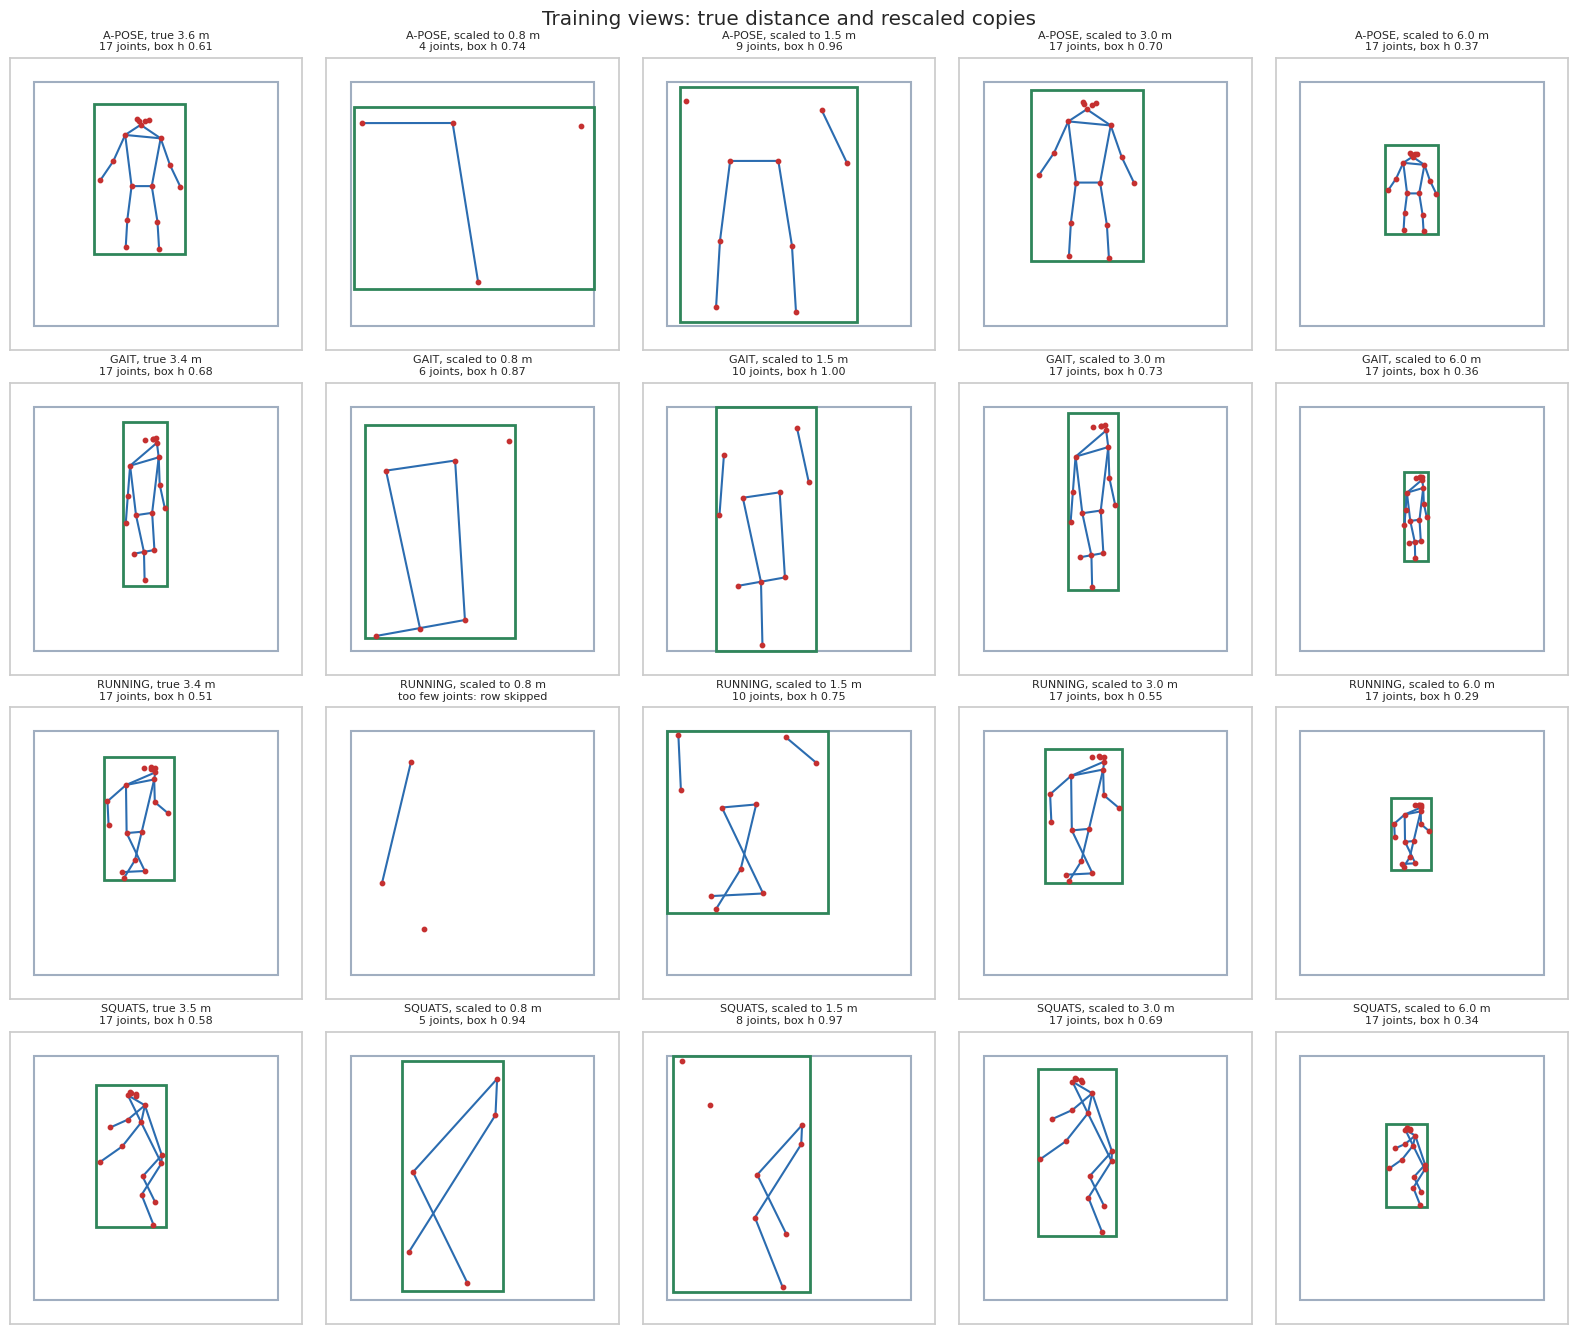

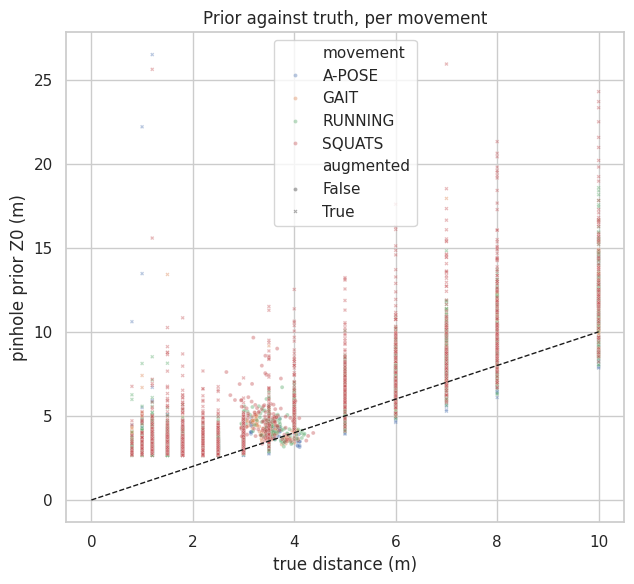

,subject,movement,camera,distance_m,augmented,z0_m,rel_h,rel_w,aspect,cx_norm,...,inv_rel_h,log_z0,det_conf,pose_available,pose_height_rel,shoulder_width_rel,hip_width_rel,torso_rel,pose_conf_mean,pose_inv_height
36788,TDB_004_F,A-POSE,36,3.5,True,5.186,0.512,0.068,7.525,0.414,...,1.952,1.646,0.937,1.0,0.440,0.001,0.003,0.167,0.937,2.273
13018,TDB_002_F,A-POSE,32,10.0,True,11.988,0.222,0.110,2.023,0.476,...,4.512,2.484,0.990,1.0,0.188,0.040,0.025,0.060,0.990,5.327
41299,TDB_004_F,GAIT,16,3.5,True,4.886,0.544,0.209,2.598,0.389,...,1.839,1.586,0.981,1.0,0.480,0.113,0.056,0.173,0.981,2.085
15409,TDB_002_F,GAIT,32,2.2,True,2.904,0.915,0.313,2.921,0.363,...,1.093,1.066,0.995,1.0,0.854,0.141,0.116,0.251,0.995,1.171
16904,TDB_002_F,RUNNING,20,10.0,True,12.986,0.205,0.105,1.953,0.472,...,4.888,2.564,0.974,1.0,0.165,0.038,0.025,0.056,0.974,6.061
30494,TDB_003_M,RUNNING,24,1.8,True,3.339,0.796,0.569,1.399,0.418,...,1.257,1.206,0.871,1.0,0.000,0.000,0.064,0.000,0.871,0.000
9952,TDB_001_F,SQUATS,40,5.0,True,7.538,0.352,0.246,1.432,0.378,...,2.837,2.020,0.908,1.0,0.314,0.077,0.048,0.120,0.908,3.183
24634,TDB_002_F,SQUATS,0,2.2,True,3.037,0.875,0.339,2.576,0.328,...,1.143,1.111,0.952,1.0,0.000,0.020,0.007,0.298,0.952,0.000


In [12]:
COCO_EDGES = [(5, 6), (5, 7), (7, 9), (6, 8), (8, 10), (5, 11), (6, 12), (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (0, 5), (0, 6)]
PREVIEW_DISTANCES = ["true", 0.8, 1.5, 3.0, 6.0]
preview_rng = np.random.default_rng(SEED)

preview_views = []
for movement in MOVEMENTS:
    rows_m = usable[usable["movement"] == movement]
    if rows_m.empty:
        continue
    subject = rows_m["subject"].iloc[0]
    meta = json.loads((DATA_DIR / f"{subject}__{movement}__KP2D.json").read_text())
    trc = load_trc_frames(DATA_DIR / f"{subject}__{movement}__KP3D.trc")
    all_k = [np.asarray(ann["keypoints_scores"], dtype=float).reshape(33, 3) for ann in meta["annotations"]]
    img_wh = estimate_image_size(all_k)
    for ann in meta["annotations"][len(meta["annotations"]) // 2:]:
        if int(ann["frame"]) in trc:
            xyz = trc[int(ann["frame"])]
            P = np.asarray(ann["proj_matrix"], dtype=float).reshape(3, 4)
            z_ref = float(np.linalg.norm(0.5 * (xyz[23] + xyz[24]) - camera_center_from_P(P)))
            preview_views.append((subject, movement, np.asarray(ann["keypoints_scores"], dtype=float).reshape(33, 3), img_wh, z_ref))
            break

fig, axes = plt.subplots(len(preview_views), len(PREVIEW_DISTANCES), figsize=(3.2 * len(PREVIEW_DISTANCES), 3.4 * len(preview_views)), squeeze=False)
for row_axes, (subject, movement, kps0, img_wh, z_ref) in zip(axes, preview_views):
    w, h = img_wh
    for ax, target in zip(row_axes, PREVIEW_DISTANCES):
        z = z_ref if target == "true" else float(target)
        kps = kps0 if target == "true" else scale_keypoints_for_distance(kps0, z_ref, z, (w / 2.0, h / 2.0))
        coco = kps[MP_TO_COCO].copy()
        outside = (coco[:, 0] < 0) | (coco[:, 0] >= w) | (coco[:, 1] < 0) | (coco[:, 1] >= h)
        coco[outside, 2] = 0.0
        ok = coco[:, 2] >= KPT_CONF
        ax.add_patch(plt.Rectangle((0, 0), w, h, fill=False, edgecolor="#a0aec0", linewidth=1.5))
        for a, b in COCO_EDGES:
            if ok[a] and ok[b]:
                ax.plot([coco[a, 0], coco[b, 0]], [coco[a, 1], coco[b, 1]], color="#2b6cb0", linewidth=1.5)
        ax.scatter(coco[ok, 0], coco[ok, 1], s=10, color="#c53030", zorder=3)
        title = f"{movement}, {'true' if target == 'true' else 'scaled to'} {z:.1f} m"
        try:
            feats, _ = view_features(kps, img_wh, preview_rng)
            x1 = (feats[3] - feats[1] / 2) * w
            y1 = (feats[4] - feats[0] / 2) * h
            ax.add_patch(plt.Rectangle((x1, y1), feats[1] * w, feats[0] * h, fill=False, edgecolor="#2f855a", linewidth=2))
            title += f"\n{int(ok.sum())} joints, box h {feats[0]:.2f}"
        except ValueError:
            title += "\ntoo few joints: row skipped"
        ax.set_xlim(-0.1 * w, 1.1 * w)
        ax.set_ylim(1.1 * h, -0.1 * h)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(title, fontsize=8)
plt.suptitle("Training views: true distance and rescaled copies")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "preview_views.png", dpi=140)
plt.show()

sample = df.groupby("movement", group_keys=False).apply(lambda g: g.sample(min(1500, len(g)), random_state=SEED))
fig, ax = plt.subplots(figsize=(6.5, 6))
sns.scatterplot(data=sample, x="distance_m", y="z0_m", hue="movement", style="augmented", s=8, alpha=0.4, ax=ax)
ax.plot([0, 10], [0, 10], "k--", linewidth=1)
ax.set_xlabel("true distance (m)")
ax.set_ylabel("pinhole prior Z0 (m)")
ax.set_title("Prior against truth, per movement")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "preview_prior_vs_truth.png", dpi=140)
plt.show()

save_table(df.groupby("movement").sample(2, random_state=SEED)[["subject", "movement", "camera", "distance_m", "augmented", "z0_m"] + FEATURE_NAMES].round(3), "preview_rows")

## 3. Exploratory data analysis and PCA

Distance histogram, how far the pinhole prior is from the truth (its spread is what the network has to correct: subject height, camera focal length, posture), and PCA of scaled features coloured by distance.

,distance_m
count,49787.000000
mean,4.071114
std,2.684923
min,0.800000
25%,1.800000
50%,3.342649
75%,6.000000
max,10.000000


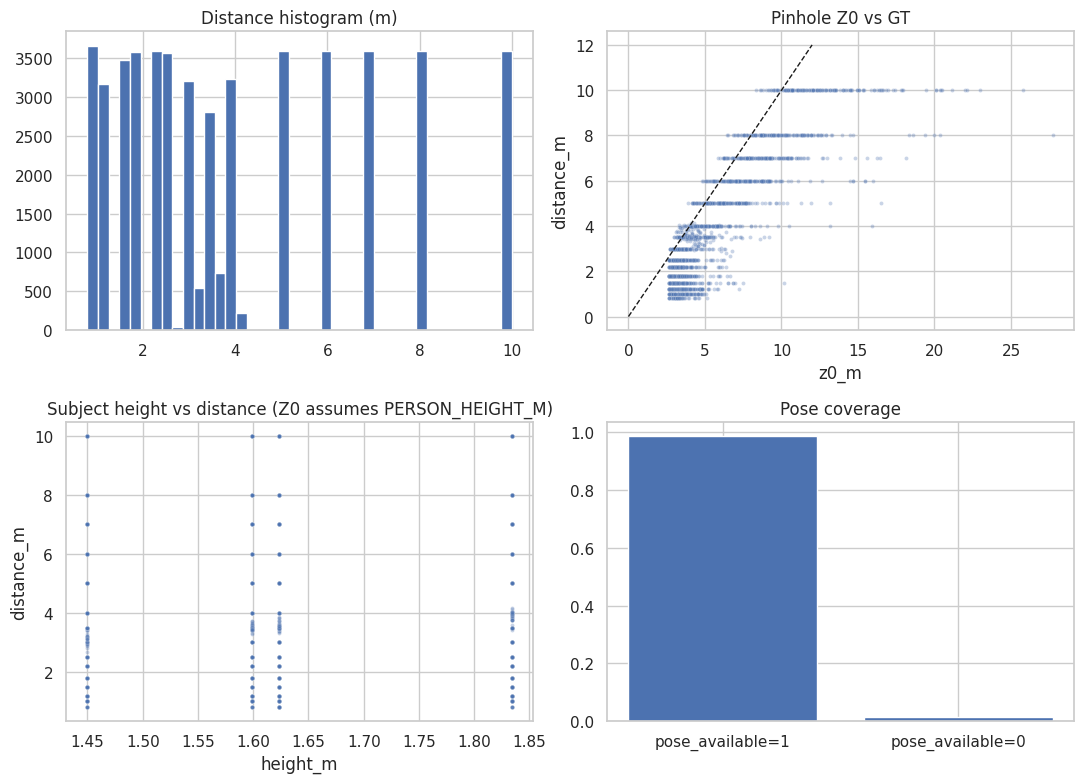

,count,mean,std,min,25%,50%,75%,max
movement,,,,,,,,
A-POSE,676.0,1.713,1.561,0.754,1.096,1.283,1.756,22.195
GAIT,19841.0,1.753,2.615,0.813,1.155,1.375,1.922,308.044
RUNNING,9941.0,1.644,0.827,0.786,1.157,1.356,1.765,9.288
SQUATS,19329.0,1.859,2.014,0.791,1.212,1.506,2.109,141.952


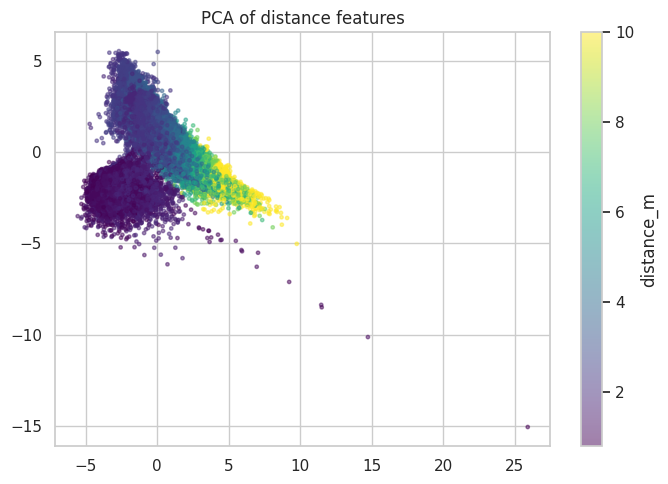

In [13]:
save_table(df["distance_m"].describe().to_frame("distance_m"), "eda_distance")
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
df["distance_m"].hist(bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Distance histogram (m)")
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=SEED), x="z0_m", y="distance_m", alpha=0.3, s=8, ax=axes[0, 1])
axes[0, 1].plot([0, 12], [0, 12], "k--", lw=1)
axes[0, 1].set_title("Pinhole Z0 vs GT")
sns.scatterplot(data=df.sample(min(2000, len(df)), random_state=SEED), x="height_m", y="distance_m", alpha=0.3, s=8, ax=axes[1, 0])
axes[1, 0].set_title("Subject height vs distance (Z0 assumes PERSON_HEIGHT_M)")
pose_rate = float(df["pose_available"].mean())
axes[1, 1].bar(["pose_available=1", "pose_available=0"], [pose_rate, 1 - pose_rate])
axes[1, 1].set_title("Pose coverage")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "eda_distance_overview.png", dpi=140)
plt.show()

prior_error = df.assign(prior_ratio=df["z0_m"] / df["distance_m"]).groupby("movement")["prior_ratio"].describe()
save_table(prior_error.round(3), "eda_prior_ratio_by_movement")

scaler = StandardScaler()
X_feat = df[FEATURE_NAMES].to_numpy(dtype=np.float32)
coords = PCA(n_components=2, random_state=SEED).fit_transform(scaler.fit_transform(X_feat))
pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "distance_m": df["distance_m"].values})
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pca_df["PC1"], pca_df["PC2"], c=pca_df["distance_m"], cmap="viridis", s=6, alpha=0.5)
plt.colorbar(sc, ax=ax, label="distance_m")
ax.set_title("PCA of distance features")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pca_distance_features.png", dpi=140)
plt.show()

## 4. Test subject and cross-validation folds

`TEST_SUBJECTS` whole subjects are held out as the test set and scored once, in section 7. The other subjects form leave-one-subject-out folds: each fold trains on all but one subject and is scored on that one. The cross-validated MAE, the mean over folds, is what chooses between experiments. `cv_folds.csv` is rewritten after every fold, so a stopped session keeps what finished.

With so few subjects, early stopping in each fold watches the fold's own held-out subject. That flatters every experiment by the same small amount, so the comparison stays fair; the test subject is never touched.

In [14]:
feature_cols = FEATURE_NAMES
subjects_shuffled = list(np.random.default_rng(SEED).permutation(sorted(df["subject"].unique())))
TEST_SUBJECT_LIST = sorted(subjects_shuffled[:TEST_SUBJECTS])
CV_SUBJECTS = sorted(subjects_shuffled[TEST_SUBJECTS:])
if len(CV_SUBJECTS) < 2:
    raise ValueError(f"Cross-validation needs at least 2 subjects besides the test subject; have {CV_SUBJECTS}")

dev_df = df[df["subject"].isin(CV_SUBJECTS)].reset_index(drop=True)
test_df = df[df["subject"].isin(TEST_SUBJECT_LIST)].reset_index(drop=True)


def arrays(frame: pd.DataFrame) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    return (frame[feature_cols].to_numpy(np.float32), frame["z0_m"].to_numpy(np.float32), frame["distance_m"].to_numpy(np.float32))


save_table(pd.DataFrame({
    "subject": CV_SUBJECTS + TEST_SUBJECT_LIST,
    "role": ["cross-validation"] * len(CV_SUBJECTS) + ["test"] * len(TEST_SUBJECT_LIST),
    "rows": [int((df["subject"] == s).sum()) for s in CV_SUBJECTS + TEST_SUBJECT_LIST],
    "height_m": [height_map.get(s) for s in CV_SUBJECTS + TEST_SUBJECT_LIST],
}).set_index("subject"), "split_subjects")

,role,rows,height_m
subject,,,
TDB_001_F,cross-validation,12893,1.623
TDB_002_F,cross-validation,12052,1.599
TDB_003_M,cross-validation,11709,1.834
TDB_004_F,test,13133,1.450


## 5. Models and training utilities

`ResidualDistanceMLP` matches the live loader: its last layer starts at zero, so an untrained network returns the pinhole prior. `AbsoluteMLP` regresses Z directly, as a comparison. Both are trained by `train_mlp` with AdamW, on the GPU with the whole table in memory, printing progress every `LOG_EVERY` epochs; with a held-out set it keeps the epoch with the best held-out MAE and stops after `PATIENCE` epochs without improvement, and without one it trains a fixed number of epochs.

In [15]:
def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    return {
        "mae": float(np.mean(np.abs(err))),
        "medae": float(np.median(np.abs(err))),
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mean_rel_err": float(np.mean(np.abs(err) / np.clip(y_true, 1e-3, None))),
    }


def band_metrics(y_true, y_pred) -> pd.DataFrame:
    """MAE and relative error per distance band."""
    bands = pd.cut(y_true, DISTANCE_BANDS_M, right=False)
    frame = pd.DataFrame({"band": bands, "abs_err": np.abs(y_pred - y_true), "rel_err": np.abs(y_pred - y_true) / y_true})
    return frame.groupby("band", observed=True).agg(rows=("abs_err", "size"), mae=("abs_err", "mean"), mean_rel_err=("rel_err", "mean"))


class ResidualDistanceMLP(nn.Module):
    def __init__(self, in_dim: int = 16, hidden=(64, 32)):
        super().__init__()
        layers: List[nn.Module] = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(inplace=True), nn.Dropout(0.1)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, x):
        return self.net(x).squeeze(-1)


class AbsoluteMLP(nn.Module):
    def __init__(self, in_dim: int = 16, hidden=(64, 32)):
        super().__init__()
        layers: List[nn.Module] = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(inplace=True), nn.Dropout(0.1)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def smooth_l1_log(pred, yb):
    return nn.functional.smooth_l1_loss(torch.log(pred.clamp_min(1e-3)), torch.log(yb.clamp_min(1e-3)))


def huber_log(pred, yb, delta=0.15):
    return nn.functional.huber_loss(torch.log(pred.clamp_min(1e-3)), torch.log(yb.clamp_min(1e-3)), delta=delta)


def smooth_l1_metres(pred, yb):
    return nn.functional.smooth_l1_loss(pred, yb)

In [16]:
def mlp_predict(model: nn.Module, residual: bool, X: np.ndarray, z0: np.ndarray) -> np.ndarray:
    model.eval()
    with torch.no_grad():
        out = model(torch.from_numpy(X).to(DEVICE)).cpu().numpy()
    return z0 * np.exp(out) if residual else out


def train_mlp(
    residual: bool,
    loss_fn,
    train: Tuple[np.ndarray, np.ndarray, np.ndarray],
    held: Optional[Tuple[np.ndarray, np.ndarray, np.ndarray]] = None,
    *,
    epochs: int = MAX_EPOCHS,
    init_state: Optional[Dict[str, torch.Tensor]] = None,
    label: str = "",
) -> Tuple[nn.Module, int, List[Dict[str, float]]]:
    """Train one MLP. With held, keep the best held-out epoch and stop early; without it, run all epochs.

    The whole table is moved to the device once and shuffled there, so an epoch is a few hundred
    large steps instead of one Python call per row.
    """
    torch.manual_seed(SEED)
    model = (ResidualDistanceMLP if residual else AbsoluteMLP)(len(FEATURE_NAMES), HIDDEN).to(DEVICE)
    if init_state is not None:
        model.load_state_dict(init_state)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    X, z0, y = (torch.from_numpy(a).to(DEVICE) for a in train)
    if held is not None:
        X_held, z0_held, y_held = (torch.from_numpy(a).to(DEVICE) for a in held)
    order_gen = torch.Generator(device=DEVICE).manual_seed(SEED)
    best_mae, best_epoch, best_state, stale = float("inf"), epochs, None, 0
    history = []
    started = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(y), device=DEVICE, generator=order_gen)
        for start in range(0, len(order), BATCH_SIZE):
            idx = order[start:start + BATCH_SIZE]
            out = model(X[idx])
            pred = z0[idx] * torch.exp(out) if residual else out
            loss = loss_fn(pred, y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        if held is None:
            if epoch % LOG_EVERY == 0 or epoch == epochs:
                print(f"  {label} epoch {epoch}/{epochs} ({time.time() - started:.0f} s)")
            continue
        model.eval()
        with torch.no_grad():
            out = model(X_held)
            pred = z0_held * torch.exp(out) if residual else out
            held_mae = float(torch.mean(torch.abs(pred - y_held)))
        history.append({"epoch": epoch, "held_out_mae": held_mae})
        if held_mae < best_mae:
            best_mae, best_epoch, stale = held_mae, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        if epoch % LOG_EVERY == 0 or stale >= PATIENCE:
            print(f"  {label} epoch {epoch} | held-out MAE {held_mae:.3f} m | best {best_mae:.3f} m at epoch {best_epoch} ({time.time() - started:.0f} s)")
        if stale >= PATIENCE:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_epoch, history

## 6. Experiments

| Id | Method | Question it answers |
|----|--------|---------------------|
| dist_exp01_pinhole_z0 | Pinhole Z0 only | How far does the prior alone get? |
| dist_exp02_ridge | Ridge regression on the features, predicting Z | Is a linear model enough? |
| dist_exp03_residual_mlp | Residual MLP, smooth L1 on log Z (the SAMS architecture) | Does a learned correction beat the prior? |
| dist_exp04_absolute_mlp | MLP predicting Z directly | Does the pinhole prior help the network? |
| dist_exp05_residual_pose_only | Residual MLP trained only on rows with pose, scored on every row | Do rows without joints hurt training? |
| dist_exp06_residual_log_huber | Residual MLP, Huber loss on log Z | Is a tighter robust loss better? |

Every experiment is scored by leave-one-subject-out cross-validation over `CV_SUBJECTS`. For the MLPs, the final model of an experiment is then trained on every cross-validation subject for the median best epoch of its folds. The live service can only serve the residual formula, so the promoted model is the residual experiment with the lowest cross-validated MAE.

In [17]:
EXPERIMENT_SPECS = {
    "dist_exp01_pinhole_z0": {"approach": "Pinhole Z0", "kind": "pinhole"},
    "dist_exp02_ridge": {"approach": "Ridge on features", "kind": "ridge"},
    "dist_exp03_residual_mlp": {"approach": "Residual MLP - SAMS Z=Z0*exp(delta)", "kind": "mlp", "residual": True, "loss": smooth_l1_log},
    "dist_exp04_absolute_mlp": {"approach": "Absolute MLP - direct Z regression", "kind": "mlp", "residual": False, "loss": smooth_l1_metres},
    "dist_exp05_residual_pose_only": {"approach": "Residual MLP - trained on pose_available rows", "kind": "mlp", "residual": True, "loss": smooth_l1_log, "pose_only": True},
    "dist_exp06_residual_log_huber": {"approach": "Residual MLP - Huber loss on log(Z)", "kind": "mlp", "residual": True, "loss": huber_log},
}
POSE_COL = FEATURE_NAMES.index("pose_available")


def training_rows(frame: pd.DataFrame, spec: Dict[str, Any]) -> pd.DataFrame:
    if spec.get("pose_only"):
        return frame[frame["pose_available"] > 0.5]
    return frame


def fit(spec: Dict[str, Any], train_frame: pd.DataFrame, held_frame: Optional[pd.DataFrame] = None, epochs: int = MAX_EPOCHS, label: str = ""):
    """Fit one experiment. Returns (predict function, best epoch or None, model or None)."""
    train_frame = training_rows(train_frame, spec)
    if spec["kind"] == "pinhole":
        return (lambda frame: frame["z0_m"].to_numpy()), None, None
    if spec["kind"] == "ridge":
        ridge = Ridge(alpha=1.0).fit(train_frame[feature_cols].to_numpy(), train_frame["distance_m"].to_numpy())
        return (lambda frame: ridge.predict(frame[feature_cols].to_numpy())), None, None
    held = arrays(held_frame) if held_frame is not None else None
    model, best_epoch, _ = train_mlp(spec["residual"], spec["loss"], arrays(train_frame), held, epochs=epochs, label=label)

    def predict(frame):
        X, z0, _ = arrays(frame)
        return mlp_predict(model, spec["residual"], X, z0)

    return predict, best_epoch, model


CV_ROWS = []
CV_SUMMARY = {}
for exp_id, spec in EXPERIMENT_SPECS.items():
    fold_epochs = []
    for held_subject in CV_SUBJECTS:
        train_frame = dev_df[dev_df["subject"] != held_subject]
        held_frame = dev_df[dev_df["subject"] == held_subject]
        print(f"{exp_id} | holding out {held_subject} | {len(train_frame):,} training rows")
        predict, best_epoch, _ = fit(spec, train_frame, held_frame, label=f"{exp_id}/{held_subject}")
        metrics = regression_metrics(held_frame["distance_m"], predict(held_frame))
        CV_ROWS.append({"experiment_id": exp_id, "held_out_subject": held_subject, "best_epoch": best_epoch, **metrics})
        pd.DataFrame(CV_ROWS).to_csv(RESULTS_DIR / "cv_folds.csv", index=False)
        if best_epoch is not None:
            fold_epochs.append(best_epoch)
        print(f"{exp_id} | held out {held_subject} | MAE {metrics['mae']:.3f} m")
    folds = pd.DataFrame([r for r in CV_ROWS if r["experiment_id"] == exp_id])
    CV_SUMMARY[exp_id] = {
        "approach": spec["approach"],
        "cv_mae": float(folds["mae"].mean()),
        "cv_mae_std": float(folds["mae"].std()),
        "cv_mean_rel_err": float(folds["mean_rel_err"].mean()),
        "final_epochs": int(np.median(fold_epochs)) if fold_epochs else None,
    }

save_table(pd.DataFrame(CV_ROWS).set_index(["experiment_id", "held_out_subject"]).round(4), "cv_folds")
cv_table = pd.DataFrame(CV_SUMMARY).T.sort_values("cv_mae")
save_table(cv_table, "cv_summary")

dist_exp01_pinhole_z0 | holding out TDB_001_F | 23,761 training rows
dist_exp01_pinhole_z0 | held out TDB_001_F | MAE 1.669 m
dist_exp01_pinhole_z0 | holding out TDB_002_F | 24,602 training rows
dist_exp01_pinhole_z0 | held out TDB_002_F | MAE 1.505 m
dist_exp01_pinhole_z0 | holding out TDB_003_M | 24,945 training rows
dist_exp01_pinhole_z0 | held out TDB_003_M | MAE 1.252 m
dist_exp02_ridge | holding out TDB_001_F | 23,761 training rows
dist_exp02_ridge | held out TDB_001_F | MAE 0.558 m
dist_exp02_ridge | holding out TDB_002_F | 24,602 training rows
dist_exp02_ridge | held out TDB_002_F | MAE 0.517 m
dist_exp02_ridge | holding out TDB_003_M | 24,945 training rows
dist_exp02_ridge | held out TDB_003_M | MAE 0.789 m
dist_exp03_residual_mlp | holding out TDB_001_F | 23,761 training rows
  dist_exp03_residual_mlp/TDB_001_F epoch 10 | held-out MAE 0.518 m | best 0.518 m at epoch 10 (1 s)
  dist_exp03_residual_mlp/TDB_001_F epoch 20 | held-out MAE 0.494 m | best 0.466 m at epoch 18 (2 s)
 

best_epoch     mae   medae  \
experiment_id                 held_out_subject                               
dist_exp01_pinhole_z0         TDB_001_F                NaN  1.6691  1.2473   
                              TDB_002_F                NaN  1.5049  1.1755   
                              TDB_003_M                NaN  1.2518  0.7508   
dist_exp02_ridge              TDB_001_F                NaN  0.5575  0.4027   
                              TDB_002_F                NaN  0.5171  0.4074   
                              TDB_003_M                NaN  0.7890  0.6151   
dist_exp03_residual_mlp       TDB_001_F               34.0  0.4028  0.3082   
                              TDB_002_F               97.0  0.2937  0.2218   
                              TDB_003_M               94.0  0.6323  0.4906   
dist_exp04_absolute_mlp       TDB_001_F               79.0  0.3327  0.2490   
                              TDB_002_F               97.0  0.3125  0.2428   
                              TDB_003_M               48.0  0.6552  0.4641   
dist_exp05_residual_pose_only TDB_001_F               73.0  0.3062  0.2268   
                              TDB_002_F              114.0  0.2802  0.2094   
                              TDB_003_M               76.0  0.6560  0.5179   
dist_exp06_residual_log_huber TDB_001_F              118.0  0.2861  0.2147   
                              TDB_002_F               92.0  0.2841  0.2109   
                              TDB_003_M               68.0  0.6431  0.5095   

                                                  rmse  mean_rel_err  
experiment_id                 held_out_subject                        
dist_exp01_pinhole_z0         TDB_001_F         2.2463        0.7565  
                              TDB_002_F         1.8550        0.6968  
                              TDB_003_M         3.7845        0.7217  
dist_exp02_ridge              TDB_001_F         0.8057        0.2026  
                              TDB_002_F         0.6789        0.2091  
                              TDB_003_M         1.2967        0.3355  
dist_exp03_residual_mlp       TDB_001_F         0.5477        0.1294  
                              TDB_002_F         0.4089        0.0937  
                              TDB_003_M         0.8325        0.1718  
dist_exp04_absolute_mlp       TDB_001_F         0.4541        0.1157  
                              TDB_002_F         0.4170        0.1044  
                              TDB_003_M         1.4744        0.2208  
dist_exp05_residual_pose_only TDB_001_F         0.4211        0.1077  
                              TDB_002_F         0.3918        0.0911  
                              TDB_003_M         0.8510        0.1815  
dist_exp06_residual_log_huber TDB_001_F         0.3901        0.1028  
                              TDB_002_F         0.3921        0.0926  
                              TDB_003_M         0.8370        0.1789

,approach,cv_mae,cv_mae_std,cv_mean_rel_err,final_epochs
dist_exp06_residual_log_huber,Residual MLP - Huber loss on log(Z),0.40444,0.206722,0.12479,92
dist_exp05_residual_pose_only,Residual MLP - trained on pose_available rows,0.414148,0.209854,0.126736,76
dist_exp04_absolute_mlp,Absolute MLP - direct Z regression,0.433466,0.192302,0.146977,79
dist_exp03_residual_mlp,Residual MLP - SAMS Z=Z0*exp(delta),0.442912,0.172832,0.131639,94
dist_exp02_ridge,Ridge on features,0.621193,0.146702,0.24906,None
dist_exp01_pinhole_z0,Pinhole Z0,1.475269,0.21025,0.725006,None


## 7. Choose, test once, and export

Every experiment is refit on all cross-validation subjects (MLPs for their `final_epochs`) and scored once on the test subject. The promoted model is the residual experiment with the lowest **cross-validated** MAE; the test column is reported, not used to choose.

Each experiment folder gets `model.pt` (MLPs) and `metadata.json` with `metrics_cv` and `metrics_holdout`. Only the promoted folder also gets `metrics_test`, because the live service serves the residual folder with the lowest `metrics_test.mae`. `distance_nn.pt` is a copy of the promoted weights, and `calib.json` records the single `fy` and `fy_image_h` the table was built with.

dist_exp01_pinhole_z0 | final fit on [np.str_('TDB_001_F'), np.str_('TDB_002_F'), np.str_('TDB_003_M')]
dist_exp02_ridge | final fit on [np.str_('TDB_001_F'), np.str_('TDB_002_F'), np.str_('TDB_003_M')]
dist_exp03_residual_mlp | final fit on [np.str_('TDB_001_F'), np.str_('TDB_002_F'), np.str_('TDB_003_M')]
  dist_exp03_residual_mlp epoch 10/94 (1 s)
  dist_exp03_residual_mlp epoch 20/94 (1 s)
  dist_exp03_residual_mlp epoch 30/94 (2 s)
  dist_exp03_residual_mlp epoch 40/94 (3 s)
  dist_exp03_residual_mlp epoch 50/94 (3 s)
  dist_exp03_residual_mlp epoch 60/94 (4 s)
  dist_exp03_residual_mlp epoch 70/94 (4 s)
  dist_exp03_residual_mlp epoch 80/94 (5 s)
  dist_exp03_residual_mlp epoch 90/94 (6 s)
  dist_exp03_residual_mlp epoch 94/94 (6 s)
dist_exp04_absolute_mlp | final fit on [np.str_('TDB_001_F'), np.str_('TDB_002_F'), np.str_('TDB_003_M')]
  dist_exp04_absolute_mlp epoch 10/79 (1 s)
  dist_exp04_absolute_mlp epoch 20/79 (1 s)
  dist_exp04_absolute_mlp epoch 30/79 (2 s)
  dist_exp04_

,approach,cv_mae,cv_mae_std,test_mae,test_medae,test_rmse,test_mean_rel_err
dist_exp06_residual_log_huber,Residual MLP - Huber loss on log(Z),0.4044,0.2067,0.5046,0.3939,0.6638,0.1414
dist_exp05_residual_pose_only,Residual MLP - trained on pose_available rows,0.4141,0.2099,0.5042,0.3424,0.7184,0.1341
dist_exp04_absolute_mlp,Absolute MLP - direct Z regression,0.4335,0.1923,0.5773,0.3970,0.7798,0.1471
dist_exp03_residual_mlp,Residual MLP - SAMS Z=Z0*exp(delta),0.4429,0.1728,0.5055,0.3638,0.6963,0.1367
dist_exp02_ridge,Ridge on features,0.6212,0.1467,0.8213,0.6405,1.1077,0.2406
dist_exp01_pinhole_z0,Pinhole Z0,1.4753,0.2102,2.9278,2.1487,3.7940,0.9511


Promoted: dist_exp06_residual_log_huber | cv MAE 0.404 | test MAE 0.505
Wrote calib.json and distance_nn.pt


dist_exp06_residual_log_huber                      \
                                      rows    mae mean_rel_err   
band                                                             
[0.0, 1.5)                            1664  0.229        0.227   
[1.5, 3.0)                            3989  0.292        0.144   
[3.0, 6.0)                            3640  0.515        0.128   
[6.0, 100.0)                          3840  0.836        0.114   

             dist_exp01_pinhole_z0                      
                              rows    mae mean_rel_err  
band                                                    
[0.0, 1.5)                    1664  2.415        2.292  
[1.5, 3.0)                    3989  2.019        1.055  
[3.0, 6.0)                    3640  2.345        0.595  
[6.0, 100.0)                  3840  4.648        0.600

,rows,promoted MAE,pinhole MAE
movement,,,
A-POSE,169,0.390,2.057
GAIT,6272,0.465,2.254
RUNNING,1984,0.570,2.741
SQUATS,4708,0.533,3.935


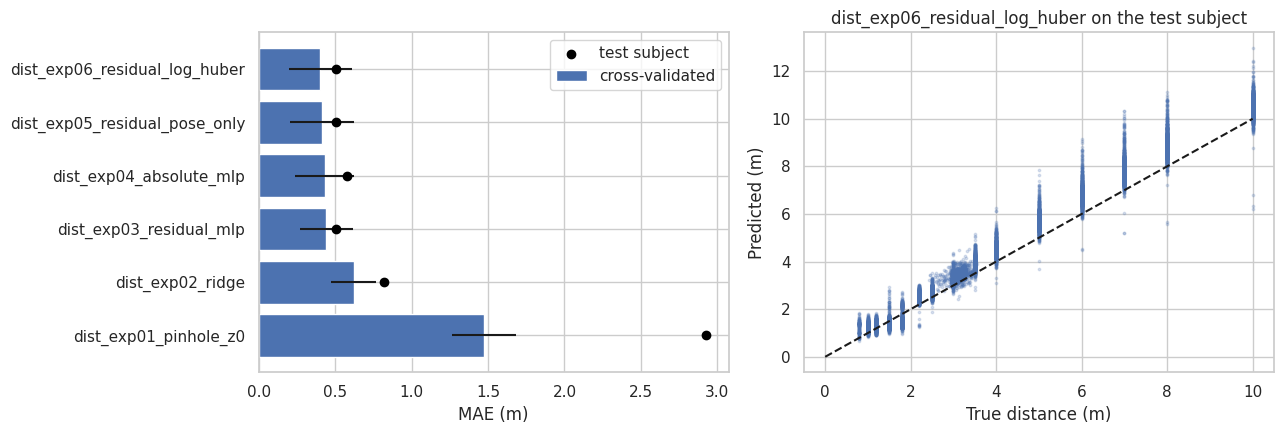

748

In [18]:
residual_ids = [exp_id for exp_id in cv_table.index if EXPERIMENT_SPECS[exp_id].get("residual")]
PROMOTED_ID = residual_ids[0]

LEDGER = []
TEST_PREDICTIONS = {}
for exp_id, spec in EXPERIMENT_SPECS.items():
    summary = CV_SUMMARY[exp_id]
    print(f"{exp_id} | final fit on {CV_SUBJECTS}")
    predict, _, model = fit(spec, dev_df, None, epochs=summary["final_epochs"] or MAX_EPOCHS, label=exp_id)
    TEST_PREDICTIONS[exp_id] = predict(test_df)
    holdout = regression_metrics(test_df["distance_m"], TEST_PREDICTIONS[exp_id])
    LEDGER.append({"experiment_id": exp_id, "approach": spec["approach"], "cv_mae": summary["cv_mae"],
                   "cv_mae_std": summary["cv_mae_std"], **{f"test_{k}": v for k, v in holdout.items()}})
    if model is None:
        continue
    out = MODELS_DIR / exp_id
    out.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), out / "model.pt")
    meta = {
        "experiment_id": exp_id,
        "approach": spec["approach"],
        "dataset": DOI,
        "feature_names": FEATURE_NAMES,
        "hidden": list(HIDDEN),
        "formula": "Z = Z0 * exp(delta)" if spec["residual"] else "Z = MLP(features)",
        "trained_on_subjects": CV_SUBJECTS,
        "test_subjects": TEST_SUBJECT_LIST,
        "epochs": summary["final_epochs"],
        "metrics_cv": {"mae": summary["cv_mae"], "mae_std": summary["cv_mae_std"], "mean_rel_err": summary["cv_mean_rel_err"]},
        "metrics_holdout": holdout,
        "promoted": exp_id == PROMOTED_ID,
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }
    if exp_id == PROMOTED_ID:
        meta["metrics_test"] = holdout
    (out / "metadata.json").write_text(json.dumps(meta, indent=2))

comparison = pd.DataFrame(LEDGER).set_index("experiment_id").loc[cv_table.index]
save_table(comparison.round(4), "experiment_comparison")
print("Promoted:", PROMOTED_ID, "| cv MAE", round(CV_SUMMARY[PROMOTED_ID]["cv_mae"], 3), "| test MAE", round(comparison.loc[PROMOTED_ID, "test_mae"], 3))

torch.save(torch.load(MODELS_DIR / PROMOTED_ID / "model.pt", map_location="cpu", weights_only=True), MODELS_DIR / "distance_nn.pt")
calib = {
    "fy_px": FY_PX,
    "fy_image_h": FY_IMAGE_H,
    "person_height_m": PERSON_HEIGHT_M,
    "tof_near_m": TOF_NEAR_M,
    "kpt_conf": KPT_CONF,
    "hidden": list(HIDDEN),
    "feature_names": FEATURE_NAMES,
    "best_experiment_id": PROMOTED_ID,
    "dataset": DOI,
}
with open(MODELS_DIR / "calib.json", "w") as f:
    json.dump(calib, f, indent=2)
print("Wrote calib.json and distance_nn.pt")

bands = pd.concat({exp_id: band_metrics(test_df["distance_m"].to_numpy(), TEST_PREDICTIONS[exp_id]) for exp_id in [PROMOTED_ID, "dist_exp01_pinhole_z0"]}, axis=1)
save_table(bands.round(3), "test_error_by_distance_band")
movement_rows = []
for movement, rows_m in test_df.groupby("movement"):
    picks = rows_m.index.to_numpy()
    movement_rows.append({"movement": movement, "rows": len(picks),
                          "promoted MAE": float(np.mean(np.abs(TEST_PREDICTIONS[PROMOTED_ID][picks] - rows_m["distance_m"]))),
                          "pinhole MAE": float(np.mean(np.abs(TEST_PREDICTIONS["dist_exp01_pinhole_z0"][picks] - rows_m["distance_m"])))})
save_table(pd.DataFrame(movement_rows).set_index("movement").round(3), "test_error_by_movement")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(comparison.index, comparison["cv_mae"], xerr=comparison["cv_mae_std"], label="cross-validated")
axes[0].scatter(comparison["test_mae"], comparison.index, color="black", zorder=3, label="test subject")
axes[0].invert_yaxis()
axes[0].set_xlabel("MAE (m)")
axes[0].legend()
axes[1].scatter(test_df["distance_m"], TEST_PREDICTIONS[PROMOTED_ID], s=3, alpha=0.2)
axes[1].plot([0, test_df["distance_m"].max()], [0, test_df["distance_m"].max()], "k--")
axes[1].set_xlabel("True distance (m)")
axes[1].set_ylabel("Predicted (m)")
axes[1].set_title(f"{PROMOTED_ID} on the test subject")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_mae.png", dpi=140)
plt.show()

card = [
    "# SAMS distance network",
    "",
    f"- Model: {PROMOTED_ID} ({EXPERIMENT_SPECS[PROMOTED_ID]['approach']}), hidden {list(HIDDEN)}",
    f"- Data: {DOI}, subjects {CV_SUBJECTS} for training, {TEST_SUBJECT_LIST} for test, movements {MOVEMENTS}",
    f"- Prior: Z0 = fy * H / h_px with fy {FY_PX:.1f} px at image height {FY_IMAGE_H} and H = {PERSON_HEIGHT_M} m",
    f"- Cross-validated MAE (leave one subject out): {CV_SUMMARY[PROMOTED_ID]['cv_mae']:.3f} m",
    f"- Test-subject MAE: {comparison.loc[PROMOTED_ID, 'test_mae']:.3f} m (pinhole alone {comparison.loc['dist_exp01_pinhole_z0', 'test_mae']:.3f} m)",
    "- Errors per distance band: results/vision/distance/test_error_by_distance_band.csv",
    "- Limits: a ring of studio cameras, not the SAMS phone; close-range and far rows are rescaled views, not recordings. Fine-tune on site rows (section 8).",
]
(MODELS_DIR / "model_card.md").write_text("\n".join(card) + "\n")

## 8. Fine-tune on this site's labelled rows

The public dataset never saw this camera or this floor. Rows measured on site (a person standing at a taped distance, or the ToF reading for the person in its beam) fine-tune the promoted residual network. The live service serves `models/vision/distance/site/` when it exists, ahead of the public experiments.

**MLOps → Download training set** writes these rows to `datasets/vision/distance/site_labels.csv` (put it under `MyDrive/SAMS/` in Colab), with `trial_code`, every name in `FEATURE_NAMES`, `z0_m` and `distance_m`.

- Rows are split by `trial_code`, so all rows of one trial are on one side; neighbouring rows of a trial are near-identical. With fewer than three trials the rows are split into consecutive blocks in recording order instead, which keeps most neighbours together.
- The features of a site row were computed with the `calib.json` that was live when it was recorded. After deploying the `calib.json` from this run, record new site rows before fine-tuning: rows from an older calibration carry a different `log_z0`.
- The site model is written only when it beats the public model on held-out site rows.

In [19]:
SITE_CSV = DRIVE_ROOT / "datasets" / "vision" / "distance" / "site_labels.csv"
SITE_DIR = MODELS_DIR / "site"
print("Site CSV header:", ",".join(["trial_code"] + FEATURE_NAMES + ["z0_m", "distance_m"]))

if not SITE_CSV.exists():
    print(f"No site data at {SITE_CSV}. Live serving keeps {PROMOTED_ID}.")
else:
    site = pd.read_csv(SITE_CSV)
    if "z0_m" not in site:
        site["z0_m"] = np.exp(site["log_z0"])
    site = site.dropna(subset=FEATURE_NAMES + ["z0_m", "distance_m"]).reset_index(drop=True)
    trial = site["trial_code"].fillna("").astype(str) if "trial_code" in site else pd.Series([""] * len(site))
    codes = sorted(set(trial) - {""})
    split = pd.Series("train", index=site.index)
    if len(codes) >= 3:
        order = list(np.random.default_rng(SEED).permutation(codes))
        n_hold = max(1, int(round(0.2 * len(codes))))
        split[trial.isin(order[:n_hold])] = "test"
        split[trial.isin(order[n_hold:2 * n_hold])] = "val"
        split_rule = "by trial"
    else:
        n_hold = max(1, int(0.15 * len(site)))
        split.iloc[-n_hold:] = "test"
        split.iloc[-2 * n_hold:-n_hold] = "val"
        split_rule = "consecutive blocks (fewer than 3 trials)"
    save_table(split.value_counts().rename_axis("split").to_frame("rows").assign(rule=split_rule), "site_split")

    parts = {name: site[split == name] for name in ("train", "val", "test")}
    base_state = torch.load(MODELS_DIR / PROMOTED_ID / "model.pt", map_location=DEVICE, weights_only=True)
    site_model, site_epoch, site_hist = train_mlp(True, EXPERIMENT_SPECS[PROMOTED_ID]["loss"], arrays(parts["train"]), arrays(parts["val"]), init_state=base_state, label="site")

    base_model = ResidualDistanceMLP(len(FEATURE_NAMES), HIDDEN).to(DEVICE)
    base_model.load_state_dict(base_state)
    X_te, z0_te, y_te = arrays(parts["test"])
    site_comparison = pd.DataFrame([
        {"model": "public " + PROMOTED_ID, **regression_metrics(y_te, mlp_predict(base_model, True, X_te, z0_te))},
        {"model": "site fine-tune", **regression_metrics(y_te, mlp_predict(site_model, True, X_te, z0_te))},
    ]).set_index("model")
    save_table(site_comparison, "site_comparison")

    site_metrics = site_comparison.loc["site fine-tune"].to_dict()
    if site_metrics["mae"] < site_comparison.iloc[0]["mae"]:
        SITE_DIR.mkdir(parents=True, exist_ok=True)
        torch.save(site_model.state_dict(), SITE_DIR / "model.pt")
        with open(SITE_DIR / "metadata.json", "w") as f:
            json.dump({
                "experiment_id": "dist_site_finetune",
                "approach": f"Residual MLP fine-tuned from {PROMOTED_ID} on site rows",
                "formula": "Z = Z0 * exp(delta)",
                "hidden": list(HIDDEN),
                "feature_names": FEATURE_NAMES,
                "source": str(SITE_CSV),
                "rows": int(len(site)),
                "split": split_rule,
                "best_epoch": site_epoch,
                "metrics_test": site_metrics,
                "public_metrics_test": site_comparison.iloc[0].to_dict(),
                "timestamp_utc": datetime.now(timezone.utc).isoformat(),
            }, f, indent=2)
        print("Site model written to", SITE_DIR)
    else:
        print("Site fine-tune did not beat the public model on held-out site rows; nothing written.")

Site CSV header: trial_code,rel_h,rel_w,aspect,cx_norm,cy_norm,bottom_y_norm,inv_rel_h,log_z0,det_conf,pose_available,pose_height_rel,shoulder_width_rel,hip_width_rel,torso_rel,pose_conf_mean,pose_inv_height,z0_m,distance_m
No site data at /content/drive/MyDrive/SAMS/datasets/vision/distance/site_labels.csv. Live serving keeps dist_exp06_residual_log_huber.
